# 03 — Real-news validation and demo

## Purpose

**What:** evaluate the saved final model (v3) on 30 real Google News headlines about Tesla, Airbus
and Siemens that were labelled by hand (`data/validation/real_news_labelled.csv`, 10 per company),
compare the result with the locked test set, and run the application offline on the latest saved
news caches as a demo.

**Why:** the test set measures the model on sentences from the same source as the training data
(Financial PhraseBank). The application, however, classifies news headlines. Only hand-labelled
real headlines show how well the model transfers to that domain.

> **Integrity rule:** this is the first time the model sees these 30 headlines. This notebook only
> *evaluates*: the model file and the labels are read, never changed, and nothing is tuned on the
> result. The labels were frozen (SHA-256) before any prediction was made.

In [1]:
# Imports and shared settings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.metrics import accuracy_score, f1_score

from newsentiment import config
from newsentiment.app import format_preprocessing
from newsentiment.classifier import classify
from newsentiment.data import load_training_data
from newsentiment.evaluation import bootstrap_ci, evaluate, load_split
from newsentiment.model import load_model
from newsentiment.news_fetcher import load_news
from newsentiment.plotting import apply_style, confusion_heatmap, save_figure
from newsentiment.preprocessing import preprocess
from newsentiment.reporter import format_report, summarise
from newsentiment.validation import COMPANIES, check_frozen, file_sha256, latest_cache, load_labels

LABELS = list(config.LABELS)  # fixed class order: negative, neutral, positive
N_BOOT = 1000  # bootstrap resamples for every confidence interval


def macro_f1(y_true, y_pred) -> float:
    """Macro-F1 over the three classes, defined exactly as in evaluate()."""
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def rel(path) -> str:
    """Path relative to the project root, for printing."""
    return path.relative_to(config.PROJECT_ROOT).as_posix()

## 1. Integrity of the labels

**What:** `check_frozen()` recomputes the SHA-256 of the labelled file and compares it with the hash
stored when the labels were frozen (`real_news_labelled.sha256`). If they differ, it raises an error
and the notebook stops here. Then `load_labels()` reads and validates the 30 labels.

**Why:** the hash proves that the labels were not edited after the model's predictions were seen.
An evaluation on changed labels would not be independent.

In [2]:
# Raises ValueError (and stops the notebook) if the labels changed since they were frozen
check_frozen()
labels_df = load_labels()
labels_sha256 = file_sha256(config.VALIDATION_LABELLED)
print(f"Frozen labels unchanged: {rel(config.VALIDATION_LABELLED)}")
print(f"SHA-256: {labels_sha256}")
assert len(labels_df) == len(COMPANIES) * config.VALIDATION_PER_COMPANY == 30

# Labels per company and class
label_counts = pd.crosstab(labels_df["company"], labels_df["label"], margins=True, margins_name="Total")
label_counts.reindex(index=[*COMPANIES, "Total"], columns=[*LABELS, "Total"], fill_value=0)

Frozen labels unchanged: data/validation/real_news_labelled.csv
SHA-256: 3d8eaf7fae2946e93001f6b8292b2515c0e26147c6d05abf6468cfaa96ec3b48


label,negative,neutral,positive,Total
company,,,,
Tesla,5,3,2,10
Airbus,0,7,3,10
Siemens,1,1,8,10
Total,6,11,13,30


## 2. Predictions

**What:** the saved final model is loaded once with `load_model()` and `classify()` predicts the 30
titles, exactly as the application does: predicted label, confidence (highest class probability)
and the `low_confidence` flag (confidence below 0.5). The titles in the sheet are already cleaned by
`preprocess()` (publisher suffix removed), because the sheet was sampled from preprocessed caches.
The table is saved as `outputs/metrics/real_news_predictions.csv`.

**Why:** one fixed prediction per headline from the unchanged model file; every later section only
summarises this table.

In [3]:
model = load_model()  # saved final model; read only
meta = json.loads(config.MODEL_METADATA_FILE.read_text(encoding="utf-8"))
print(f"Model: {rel(config.MODEL_FILE)} (iteration {meta['iteration']}, trained {meta['training_date']})")

# Predict the 30 titles; "sentiment" (the classifier's column name) becomes "prediction"
classified = classify(labels_df, model=model)
PREDICTION_COLUMNS = ["id", "company", "title", "label", "prediction", "confidence", "low_confidence"]
predictions = classified.rename(columns={"sentiment": "prediction"})[PREDICTION_COLUMNS]

predictions_file = config.METRICS_DIR / "real_news_predictions.csv"
predictions.to_csv(predictions_file, index=False, encoding="utf-8", lineterminator="\n")
print(f"Saved {rel(predictions_file)}")

# Shared by all later sections
y_true, y_pred = predictions["label"], predictions["prediction"]
correct = y_true == y_pred
with pd.option_context("display.max_colwidth", None):
    display(predictions)

Model: models/sentiment_model.joblib (iteration v3, trained 2026-11-10)
Saved outputs/metrics/real_news_predictions.csv


,id,company,title,label,prediction,confidence,low_confidence
0,1,Siemens,"ICS Patch Tuesday: Siemens Flags High-Severity Flaws, Node2Shell Exposure",negative,neutral,0.496,True
1,2,Airbus,Airbus Mobile hires military veterans through SkillBridge program,neutral,neutral,0.758,False
2,3,Siemens,Siemens Energy more than doubles annual profit to €4.1 billion,positive,negative,0.449,True
3,4,Airbus,Cathay boosts AIrbus A330neo order to 41 as HK Express adds A321neos,positive,positive,0.543,False
4,5,Tesla,"If You Want to Order a New Tesla Cybertruck, You’re Now Forced to Buy the $112K Cyberbeast",negative,neutral,0.542,False
5,6,Tesla,Tesla expands robotaxi service to San Antonio,positive,positive,0.729,False
6,7,Siemens,Morgan Lewis advises Lauterbach Group on the sale to Siemens,positive,neutral,0.445,True
7,8,Siemens,Siemens CEO says cooperation with Nvidia will not be affected by leadership uncertainty,neutral,positive,0.503,False
8,9,Airbus,Lufthansa Extends Airbus A340-300 Operations as Boeing 777-9 Delays Push Deliveries to 2027,neutral,neutral,0.649,False
9,10,Tesla,Form Energy Adds Meta and Tesla Veterans Lori Goler and Jon McNeill to Board as It Ramps Production for Commercial Growth,neutral,neutral,0.495,True


## 3. Metrics on the real headlines

**What:** `evaluate()` gives accuracy, macro-F1, per-class precision/recall/F1 and the confusion
matrix. For accuracy and macro-F1, `bootstrap_ci()` adds a **95 % confidence interval**: the 30
(label, prediction) pairs are resampled with replacement 1,000 times (seed
42), the metric is computed on every resample, and the 2.5th and 97.5th percentiles form the
interval. As a reference, the **"always neutral"** rule (the majority class of the training part)
is scored on the same 30 headlines. The confusion matrix is saved as `fig_confusion_real` (same
layout as `fig_confusion_test`: rows = true class, columns = predicted class, count and row
percentage per cell).

**Why:** with only 30 headlines, one more or one fewer error moves the accuracy by 3.3 points; the
interval shows how uncertain the scores are. The reference is the lower bound a useful model must
beat on the same headlines.

In [4]:
result_real = evaluate(y_true, y_pred)
assert np.isclose(macro_f1(y_true, y_pred), result_real["macro_f1"])  # same definition
ci_acc_real = bootstrap_ci(y_true, y_pred, accuracy_score, n_boot=N_BOOT)
ci_f1_real = bootstrap_ci(y_true, y_pred, macro_f1, n_boot=N_BOOT)

# Reference: the majority class of the training part, predicted for every headline
df, _ = load_training_data()
train_df, test_df = load_split(df)  # the locked split from data/split.json
majority_class = train_df["label"].value_counts().idxmax()
assert majority_class == "neutral"
ref_pred = [majority_class] * len(y_true)
result_ref = evaluate(y_true, ref_pred)
ci_acc_ref = bootstrap_ci(y_true, ref_pred, accuracy_score, n_boot=N_BOOT)
ci_f1_ref = bootstrap_ci(y_true, ref_pred, macro_f1, n_boot=N_BOOT)

pd.DataFrame(
    [
        {"predictor": "model (v3)", "n": len(y_true),
         "accuracy": result_real["accuracy"], "acc_ci_low": ci_acc_real[0], "acc_ci_high": ci_acc_real[1],
         "macro_f1": result_real["macro_f1"], "f1_ci_low": ci_f1_real[0], "f1_ci_high": ci_f1_real[1]},
        {"predictor": f"always {majority_class}", "n": len(y_true),
         "accuracy": result_ref["accuracy"], "acc_ci_low": ci_acc_ref[0], "acc_ci_high": ci_acc_ref[1],
         "macro_f1": result_ref["macro_f1"], "f1_ci_low": ci_f1_ref[0], "f1_ci_high": ci_f1_ref[1]},
    ]
).set_index("predictor").round(4)

,n,accuracy,acc_ci_low,acc_ci_high,macro_f1,f1_ci_low,f1_ci_high
predictor,,,,,,,
model (v3),30,0.4667,0.3,0.6333,0.3485,0.2175,0.4762
always neutral,30,0.3667,0.2,0.5667,0.1789,0.1111,0.2411


In [5]:
# Per-class precision, recall, F1 and support of the model on the real headlines
pd.DataFrame.from_dict(result_real["per_class"], orient="index").round(4)

,precision,recall,f1,support
negative,0.0000,0.0000,0.0000,6
neutral,0.4091,0.8182,0.5455,11
positive,0.7143,0.3846,0.5000,13


outputs/figures/fig_confusion_real.png


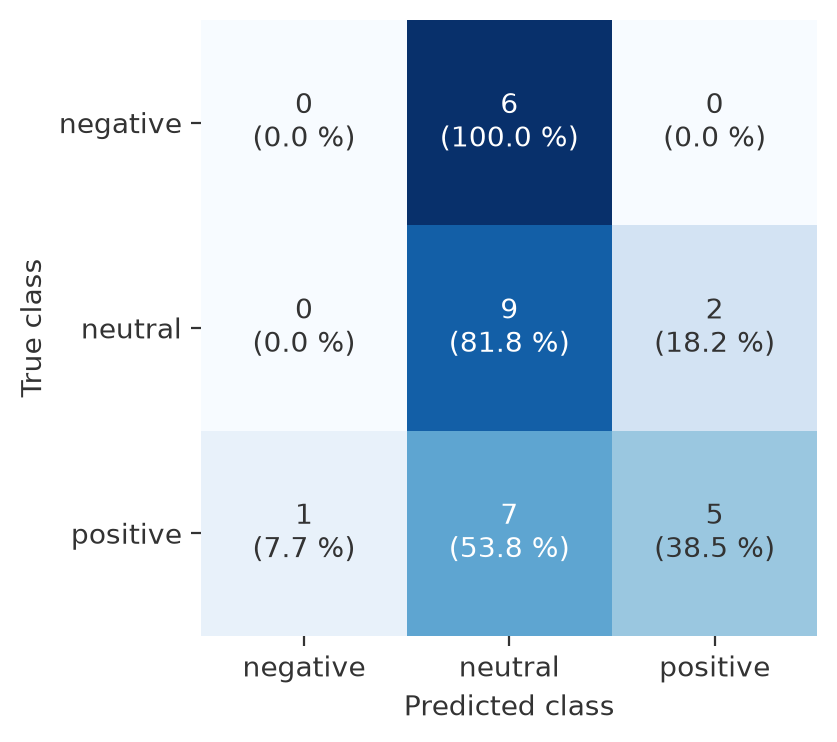

predicted,negative,neutral,positive
true,,,
negative,0,6,0
neutral,0,9,2
positive,1,7,5


In [6]:
# Figure: confusion matrix of the real headlines (rows = true, columns = predicted)
cm_real = np.array(result_real["confusion_matrix"])
fig = confusion_heatmap(cm_real, LABELS)
path = save_figure(fig, "fig_confusion_real")
print(rel(path))
display(Image(filename=str(path)))
pd.DataFrame(cm_real, index=pd.Index(LABELS, name="true"), columns=pd.Index(LABELS, name="predicted"))

## 4. Test set vs real headlines

**What:** the saved model predicts the 968 sentences of the locked test split again (no retraining;
an assert checks that the scores equal `test_results.json`). For both sets, accuracy and macro-F1
get a 95 % bootstrap interval computed the same way (1,000 resamples, same seed). The figure
`fig_domain_gap` shows the macro-F1 of both sets with the interval as whiskers.

**Why:** the test set is the in-domain estimate (Financial PhraseBank sentences); the real headlines
are the target domain of the application. The gap between the two, read together with the width of
the intervals, shows how much of the test performance carries over.

In [7]:
# Re-predict the locked test split with the saved model (the model is not refitted)
X_test, y_test = test_df["text"], test_df["label"]
test_pred = model.predict(X_test)
result_test = evaluate(y_test, test_pred)
stored = json.loads((config.METRICS_DIR / "test_results.json").read_text(encoding="utf-8"))["test_full"]
assert len(y_test) == stored["n"] == 968
assert np.isclose(result_test["accuracy"], stored["accuracy"])
assert np.isclose(result_test["macro_f1"], stored["macro_f1"])

ci_acc_test = bootstrap_ci(y_test, test_pred, accuracy_score, n_boot=N_BOOT)
ci_f1_test = bootstrap_ci(y_test, test_pred, macro_f1, n_boot=N_BOOT)

sets = {
    "test set": (len(y_test), result_test, ci_acc_test, ci_f1_test),
    "real headlines": (len(y_true), result_real, ci_acc_real, ci_f1_real),
}
gap_table = pd.DataFrame(
    [
        {"set": name, "n": n,
         "accuracy": r["accuracy"], "acc_ci_low": ca[0], "acc_ci_high": ca[1], "acc_ci_width": ca[1] - ca[0],
         "macro_f1": r["macro_f1"], "f1_ci_low": cf[0], "f1_ci_high": cf[1], "f1_ci_width": cf[1] - cf[0]}
        for name, (n, r, ca, cf) in sets.items()
    ]
).set_index("set")
gap_table.round(4)

,n,accuracy,acc_ci_low,acc_ci_high,acc_ci_width,macro_f1,f1_ci_low,f1_ci_high,f1_ci_width
set,,,,,,,,,
test set,968,0.7831,0.7562,0.8068,0.0506,0.7404,0.7057,0.7722,0.0665
real headlines,30,0.4667,0.3000,0.6333,0.3333,0.3485,0.2175,0.4762,0.2587


outputs/figures/fig_domain_gap.png


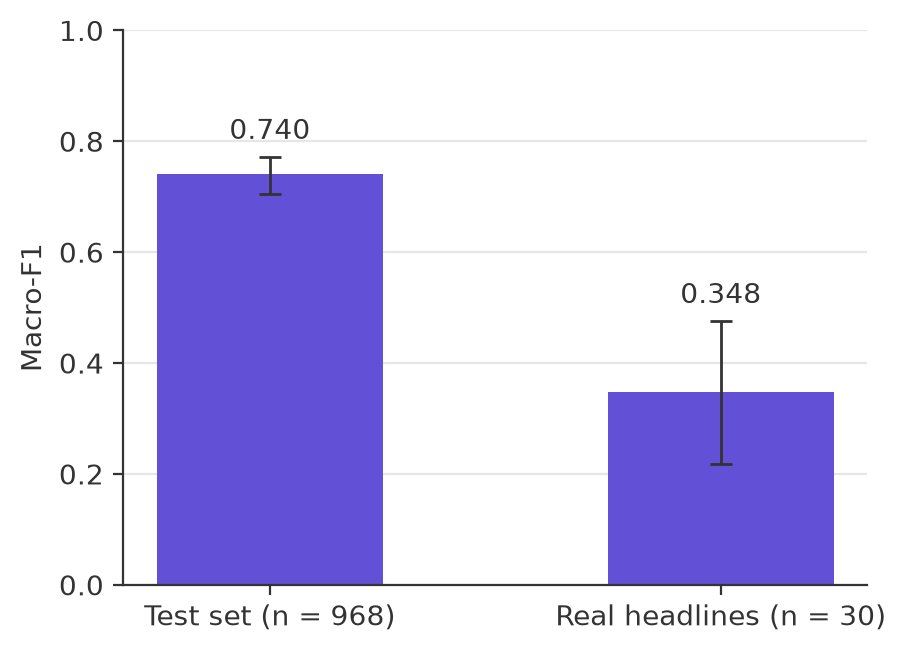

In [8]:
# Figure: macro-F1 of both sets, whiskers = 95 % bootstrap interval
names = [f"Test set (n = {len(y_test):,})", f"Real headlines (n = {len(y_true)})"]
values = np.array([result_test["macro_f1"], result_real["macro_f1"]])
lows = np.array([ci_f1_test[0], ci_f1_real[0]])
highs = np.array([ci_f1_test[1], ci_f1_real[1]])

apply_style()
fig, ax = plt.subplots(figsize=(4.8, 3.6))
x = np.arange(len(values))
ax.bar(x, values, yerr=[values - lows, highs - values], color=config.ACCENT_COLOR, width=0.5,
       error_kw={"ecolor": "#333333", "capsize": 4, "linewidth": 1})
for xi, value, high in zip(x, values, highs):
    ax.text(xi, high + 0.02, f"{value:.3f}", ha="center", va="bottom")  # value above the whisker
ax.set_xticks(x, names)
ax.set_ylim(0, 1)
ax.set_ylabel("Macro-F1")
path = save_figure(fig, "fig_domain_gap")
print(rel(path))
display(Image(filename=str(path)))

## 5. Confidence flag

**What:** `classify()` flags a prediction as low confidence when its highest class probability is
below 0.5. The accuracy of flagged and unflagged headlines is compared, with counts.

**Why:** the flag is meant to warn the reader of the report. In notebook 02 (out-of-fold, training
part) predictions below 0.5 were only about 52 % correct; this checks whether the flag also
separates weaker from stronger predictions on real headlines.

In [9]:
confidence_rows = {}
for name, mask in [("flagged", predictions["low_confidence"]), ("unflagged", ~predictions["low_confidence"])]:
    n = int(mask.sum())
    n_correct = int(correct[mask].sum())
    confidence_rows[name] = {"n": n, "correct": n_correct, "accuracy": n_correct / n if n else None}
print(f"Threshold: confidence < {config.LOW_CONFIDENCE_THRESHOLD} -> flagged")
pd.DataFrame.from_dict(confidence_rows, orient="index")

Threshold: confidence < 0.5 -> flagged


,n,correct,accuracy
flagged,6,1,0.166667
unflagged,24,13,0.541667


## 6. Per company

**What:** number of headlines, correct predictions and accuracy per company, and how the true labels
and the predictions are distributed over the three classes.

**Why:** the companies differ in their news (e.g. product news vs orders vs results). With 10
headlines each, one headline is 10 accuracy points, so this table is **descriptive only**; it does
not support conclusions about differences between companies.

In [10]:
company_rows = {}
for company in COMPANIES:
    mask = predictions["company"] == company
    part = predictions[mask]
    company_rows[company] = {
        "n": int(mask.sum()),
        "correct": int(correct[mask].sum()),
        "accuracy": float(correct[mask].mean()),
        "label_counts": {label: int((part["label"] == label).sum()) for label in LABELS},
        "prediction_counts": {label: int((part["prediction"] == label).sum()) for label in LABELS},
    }

# Flat view: accuracy plus label vs prediction counts per class
pd.DataFrame.from_dict(
    {
        company: {
            "n": r["n"], "correct": r["correct"], "accuracy": r["accuracy"],
            **{f"label_{label}": r["label_counts"][label] for label in LABELS},
            **{f"pred_{label}": r["prediction_counts"][label] for label in LABELS},
        }
        for company, r in company_rows.items()
    },
    orient="index",
)

,n,correct,accuracy,label_negative,label_neutral,label_positive,pred_negative,pred_neutral,pred_positive
Tesla,10,4,0.4,5,3,2,0,9,1
Airbus,10,7,0.7,0,7,3,0,8,2
Siemens,10,3,0.3,1,1,8,1,5,4


## 7. Errors

**What:** every misclassified headline with its true label, prediction and confidence, the most
confident errors first.

**Why:** reading the errors shows *what kind* of headline the model gets wrong, which the metrics
alone do not show.

In [11]:
errors = predictions[~correct].sort_values("confidence", ascending=False)
print(f"{len(errors)} of {len(predictions)} headlines misclassified")
with pd.option_context("display.max_colwidth", None):
    display(errors[["id", "company", "title", "label", "prediction", "confidence", "low_confidence"]])

16 of 30 headlines misclassified


,id,company,title,label,prediction,confidence,low_confidence
10,11,Tesla,Finland clears Tesla assisted driving tech after changes,positive,neutral,0.784,False
19,20,Tesla,Texas AG-elect vows 'tremendous scrutiny' of SpaceX-Tesla merger,negative,neutral,0.720,False
14,15,Airbus,Airbus A350-1000ULR Shatters Commercial Flight Distance Record in 24-Hour Qantas Test,positive,neutral,0.680,False
13,14,Airbus,Australia-France Airbus flight breaks world distance record,positive,neutral,0.657,False
22,23,Airbus,Etihad Airways Scraps All Airbus A380 Flights To North America: See Map Now,neutral,positive,0.600,False
20,21,Siemens,Siemens Energy sees higher margins as data centres boost power equipment demand,positive,neutral,0.571,False
25,26,Tesla,"Rest in gaudy peace, Tesla Cybertruck | Column",negative,neutral,0.543,False
4,5,Tesla,"If You Want to Order a New Tesla Cybertruck, You’re Now Forced to Buy the $112K Cyberbeast",negative,neutral,0.542,False
18,19,Siemens,Siemens Gamesa reaches breakeven after several challenging years,positive,neutral,0.522,False
12,13,Tesla,"Woman injured in Highway 84 crash sues Tesla, car event organizers over alleged negligence",negative,neutral,0.511,False


## 8. Demo: the application on the latest news caches

**What:** for Tesla, Airbus and Siemens the latest saved news cache (`data/news/`, the alphabetically
last file per company) is run through the same steps as the command-line application —
`preprocess()` → `classify()` → `summarise()` — and the console report is printed with
`format_report(top_n=5)`. Nothing is fetched and no result files are written. The class shares per
company are shown in `fig_company_shares`.

**Why:** the demo shows the application's output end to end. Using the saved caches instead of the
live feed makes it offline and reproducible: re-running the notebook gives the same reports. Some of
these headlines may also be among the 30 labelled ones, because the labelling sheet was sampled from
caches as well; the overlap is counted below. The demo is descriptive and is not part of the
evaluation.

In [12]:
demo = {}
for company in COMPANIES:
    cache = latest_cache(company)
    clean, prep_report = preprocess(load_news(cache), company)
    results = classify(clean, model=model)
    summary = summarise(results)
    demo[company] = {"cache": cache, "preprocessing": prep_report, "results": results, "summary": summary}

    print(f"Cache: {rel(cache)}")
    print(format_preprocessing(prep_report))
    print()
    print(format_report(results, summary, company, top_n=5))
    print()

# How many labelled headlines also appear in the demo data (same company, same title)
labelled_keys = set(zip(labels_df["company"], labels_df["title"]))
demo_keys = {(c, t) for c, d in demo.items() for t in d["results"]["title"]}
overlap = len(labelled_keys & demo_keys)
print(f"Labelled headlines that are also in the demo data: {overlap} of {len(labelled_keys)}")

Cache: data/news/tesla_20261114-1013.csv
100 fetched -> 95 kept: 0 press releases, 0 quote pages, 3 off-topic, 2 duplicates

Sentiment report: Tesla
Headlines: 95   Period: 2026-11-09 to 2026-11-14

  negative    1.1%  (1)
  neutral    86.3%  (82)
  positive   12.6%  (12)

Net sentiment: +11.6  (scale -100 to +100)
Low-confidence headlines (confidence < 0.5): 19   Mean confidence: 0.648

Latest 5 headlines (* = low confidence):
  2026-11-14  neutral  0.487* Tesla invites select customers to buy Cybercab for personal use
  2026-11-14  neutral  0.661  Tesla Opens Cybercab Purchases to Select Private Buyers
  2026-11-14  neutral  0.586  Tesla Cybercab Orders Open: $299/Month Autonomy Plan and Delivery City Pick
  2026-11-14  neutral  0.793  Tesla Starts Selling Cybercab — $30,000*
  2026-11-14  neutral  0.718  Tesla Opens Sales Of Autonomous Cybercab For ‘Select’ Customers

Cache: data/news/airbus_20261114-1013.csv
100 fetched -> 90 kept: 8 press releases, 1 quote pages, 1 off-topic, 0 du

In [13]:
# Summary per company (one row each)
demo_table = pd.DataFrame.from_dict({company: d["summary"] for company, d in demo.items()}, orient="index")
demo_table

,n,count_negative,share_negative,count_neutral,share_neutral,count_positive,share_positive,net_sentiment,mean_confidence,n_low_confidence
Tesla,95,1,0.011,82,0.863,12,0.126,11.6,0.648,19
Airbus,90,1,0.011,64,0.711,25,0.278,26.7,0.623,13
Siemens,88,5,0.057,53,0.602,30,0.341,28.4,0.588,24


outputs/figures/fig_company_shares.png


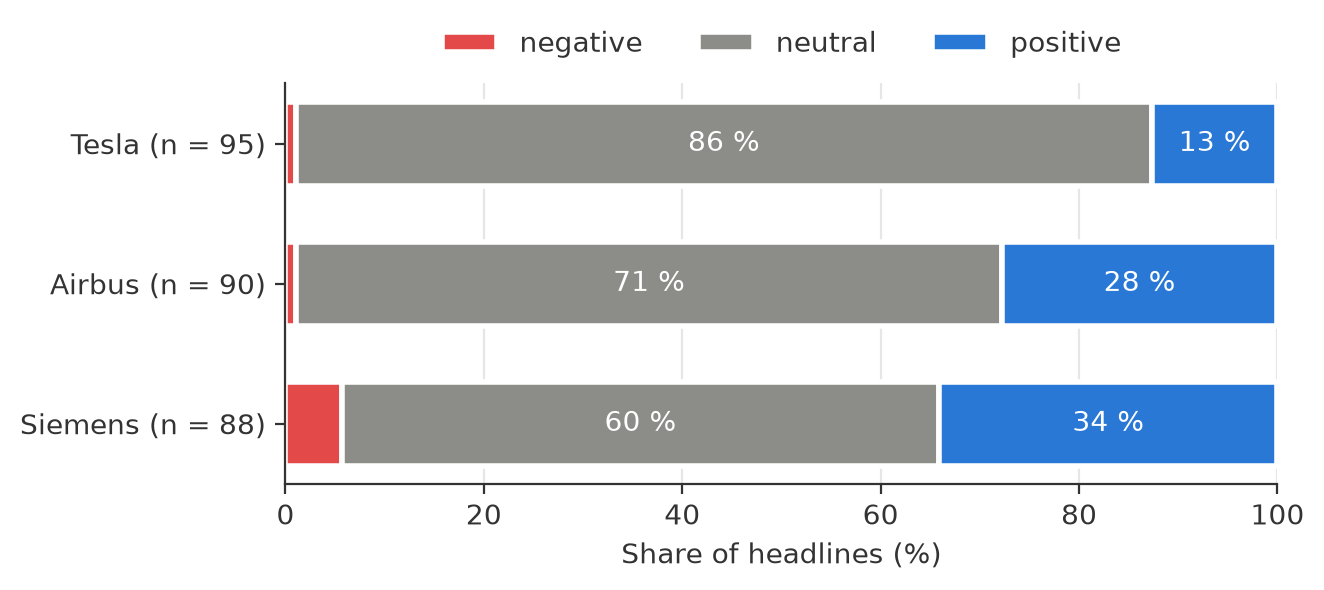

In [14]:
# Figure: 100 % stacked horizontal bars, one per company, classes in LABELS order
apply_style()
fig, ax = plt.subplots(figsize=(6.4, 2.6))
y = np.arange(len(COMPANIES))
left = np.zeros(len(COMPANIES))
for label in LABELS:
    shares = np.array(
        [demo[c]["summary"][f"count_{label}"] / demo[c]["summary"]["n"] * 100 for c in COMPANIES]
    )
    # White edge = visible gap between neighbouring segments
    ax.barh(y, shares, left=left, height=0.6, color=config.CLASS_COLORS[label],
            edgecolor="white", linewidth=2, label=label)
    for yi, (start, share) in enumerate(zip(left, shares)):
        if share >= 8:  # label only segments wide enough to hold the text
            ax.text(start + share / 2, yi, f"{share:.0f} %", ha="center", va="center", color="white")
    left += shares
ax.set_yticks(y, [f"{c} (n = {demo[c]['summary']['n']})" for c in COMPANIES])
ax.invert_yaxis()  # first company on top
ax.set_xlim(0, 100)
ax.set_xlabel("Share of headlines (%)")
ax.grid(False, axis="y")
ax.grid(True, axis="x")  # grid on the value axis
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(LABELS), frameon=False)
path = save_figure(fig, "fig_company_shares")
print(rel(path))
display(Image(filename=str(path)))

## 9. Results file and observations

**What:** all numbers of this notebook are written to `outputs/metrics/real_news_results.json`:
metrics with confidence intervals, per-class metrics, confusion matrix, the "always neutral"
reference, the test-vs-real comparison, the confidence flag, the per-company results, the error ids
and the demo summaries. The file contains no time stamp, so an unchanged re-run writes the same file.

**Why:** the report and the slides quote these numbers; one machine-readable file keeps them
traceable to this notebook.

In [15]:
def interval(pair) -> dict:
    """Confidence interval as a JSON object."""
    return {"low": pair[0], "high": pair[1]}


def scores(n, result, ci_acc, ci_f1) -> dict:
    """n, accuracy and macro-F1 with their 95 % intervals."""
    return {
        "n": int(n),
        "accuracy": result["accuracy"], "accuracy_ci95": interval(ci_acc),
        "macro_f1": result["macro_f1"], "macro_f1_ci95": interval(ci_f1),
    }


real_news_results = {
    "labels_file": rel(config.VALIDATION_LABELLED),
    "labels_sha256": labels_sha256,
    "model_file": rel(config.MODEL_FILE),
    "model_iteration": meta["iteration"],
    "bootstrap": {
        "n_boot": N_BOOT,
        "seed": config.RANDOM_SEED,
        "method": "95 % percentile interval; (label, prediction) rows resampled with replacement",
    },
    "real_headlines": {
        **scores(len(y_true), result_real, ci_acc_real, ci_f1_real),
        "per_class": result_real["per_class"],
        "labels": result_real["labels"],
        "confusion_matrix": result_real["confusion_matrix"],
    },
    "reference_always_neutral": {
        "predicted_class": majority_class,
        **scores(len(y_true), result_ref, ci_acc_ref, ci_f1_ref),
        "per_class": result_ref["per_class"],
    },
    "test_vs_real": {
        "test_set": scores(len(y_test), result_test, ci_acc_test, ci_f1_test),
        "real_headlines": scores(len(y_true), result_real, ci_acc_real, ci_f1_real),
        "accuracy_difference_real_minus_test": result_real["accuracy"] - result_test["accuracy"],
        "macro_f1_difference_real_minus_test": result_real["macro_f1"] - result_test["macro_f1"],
    },
    "confidence": {"threshold": config.LOW_CONFIDENCE_THRESHOLD, **confidence_rows},
    "per_company": company_rows,
    "errors": {"n": int(len(errors)), "ids": [int(i) for i in errors["id"]]},
    "demo": {
        company: {"cache_file": rel(d["cache"]), "preprocessing": d["preprocessing"], "summary": d["summary"]}
        for company, d in demo.items()
    },
    "demo_overlap_with_labelled": overlap,
}
results_file = config.METRICS_DIR / "real_news_results.json"
results_file.write_text(json.dumps(real_news_results, indent=2) + "\n", encoding="utf-8", newline="\n")
print(f"Saved {rel(results_file)}")

Saved outputs/metrics/real_news_results.json


### Observations

Final model v3 (`models/sentiment_model.joblib`, unchanged), evaluated once on the 30 frozen,
hand-labelled headlines (6 negative, 11 neutral, 13 positive; SHA-256 check passed). Intervals are
95 % percentile bootstrap intervals (1,000 resamples, seed 42).

- **Real headlines:** accuracy **0.467** (14 of 30 correct), 95 % CI [0.300, 0.633];
  macro-F1 **0.348**, 95 % CI [0.217, 0.476].
- **"Always neutral" reference on the same 30:** accuracy 0.367 (11 of 30), macro-F1 0.179
  (CI [0.111, 0.241]). The model is 0.100 above it in accuracy (3 headlines) and 0.170 in macro-F1;
  the two accuracy intervals overlap ([0.300, 0.633] vs [0.200, 0.567]).
- **Test set vs real headlines:** on the 968 test sentences (re-predicted with the saved model,
  identical to `test_results.json`) accuracy is 0.783 [0.756, 0.807] and macro-F1 0.740
  [0.706, 0.772]. On the real headlines macro-F1 is **0.392 lower** and accuracy 0.316 lower; the
  macro-F1 intervals do not overlap (upper bound 0.476 vs lower bound 0.706).
- **Per class (real, precision / recall / F1):** negative 0.000 / 0.000 / **0.000** (6),
  neutral 0.409 / 0.818 / **0.545** (11), positive 0.714 / 0.385 / **0.500** (13).
- **Confusion matrix:** none of the 6 negative headlines is recognised; all 6 are predicted neutral.
  7 of 13 positive headlines are predicted neutral, 1 negative. The model predicts neutral for 22 of
  30 headlines, while 11 are labelled neutral. 13 of the 16 errors are "→ neutral".
- **Confidence flag:** 6 headlines are flagged (confidence < 0.5); 1 of them is correct (0.167).
  Of the 24 unflagged headlines, 13 are correct (0.542). The most confident error has confidence
  0.784 (positive → neutral).
- **Per company (descriptive, n = 10 each):** Tesla 4 / 10 correct (labels 5 negative / 3 neutral /
  2 positive, predictions 0 / 9 / 1); Airbus 7 / 10 (labels 0 / 7 / 3, predictions 0 / 8 / 2);
  Siemens 3 / 10 (labels 1 / 1 / 8, predictions 1 / 5 / 4).
- **Demo (latest caches, 14 Nov 2026):** Tesla 95 headlines, 1.1 % negative / 86.3 % neutral /
  12.6 % positive, net sentiment +11.6, 19 low-confidence; Airbus 90 headlines, 1.1 / 71.1 / 27.8 %,
  net +26.7, 13 low-confidence; Siemens 88 headlines, 5.7 / 60.2 / 34.1 %, net +28.4,
  24 low-confidence. All 30 labelled headlines are part of these caches. Given a negative recall of
  0 of 6 on the labelled headlines, the low negative shares in the demo cannot be taken at face
  value.
- **Small-sample caveat:** one headline changes the accuracy by 3.3 points. The real-news
  intervals are 0.333 wide for accuracy and 0.259 for macro-F1, against 0.051 and 0.066 on the test
  set (about 6.6 and 4.0 times wider). The negative-class result rests on 6 headlines, and all 30
  come from one week of news about three companies. The size of the drop is therefore uncertain;
  its direction is consistent across accuracy, macro-F1 and the per-class results.

The model and the labels were not changed after this evaluation.